# 01 — EDA del Lemon Quality Dataset

Exploración del dataset Kaggle (Lemon Quality Dataset, `softwaremill/lemon-dataset`). El dataset trae 3 carpetas: `good_quality`, `bad_quality`, `empty_background`. Para Modelo A (clasificación) trabajamos como binaria: Sano vs Defectuoso. La clase `empty_background` se reserva para validar Modelo B (detección).

Salidas esperadas: distribución de clases, muestras visuales por categoría, dimensiones de imágenes, estadísticas de color, splits estratificados y decisión final sobre arquitectura.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
DATA_DIR = '../data/lemons'

In [4]:
# Construir DataFrame con (path, clase_origen)
rows = []
for cls in sorted(os.listdir(DATA_DIR)):
    cls_dir = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(cls_dir):
        continue
    for f in os.listdir(cls_dir):
        rows.append({'path': os.path.join(cls_dir, f), 'clase_origen': cls})

df = pd.DataFrame(rows)
print(f'Total imagenes: {len(df)}')
df.head()

Total imagenes: 2528


,path,clase_origen
0,../data/lemons/bad_quality/bad_quality_0.jpg,bad_quality
1,../data/lemons/bad_quality/bad_quality_1.jpg,bad_quality
2,../data/lemons/bad_quality/bad_quality_10.jpg,bad_quality
3,../data/lemons/bad_quality/bad_quality_100.jpg,bad_quality
4,../data/lemons/bad_quality/bad_quality_101.jpg,bad_quality


## Distribución de clases (3 originales)

clase_origen
good_quality        1125
bad_quality          951
empty_background     452
Name: count, dtype: int64


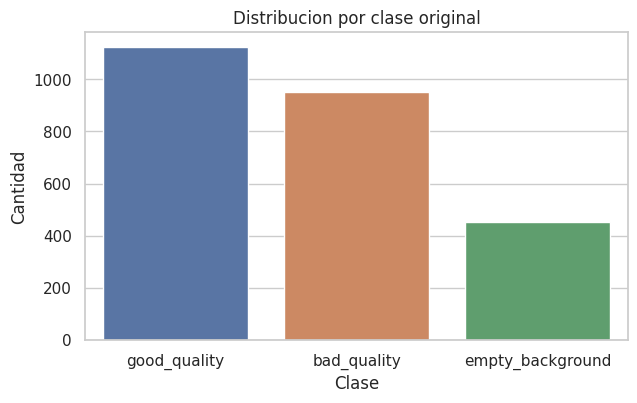

In [5]:
counts = df['clase_origen'].value_counts()
print(counts)

plt.figure(figsize=(7, 4))
sns.countplot(x='clase_origen', data=df, order=counts.index)
plt.title('Distribucion por clase original')
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.show()

## Reducción a binaria para Modelo A

Mapping: `good_quality` → Sano (0), `bad_quality` → Defectuoso (1). `empty_background` se excluye del Modelo A (lo usa Modelo B para validar detección).

In [6]:
mapping = {'good_quality': 0, 'bad_quality': 1}
df_mod_a = df[df['clase_origen'].isin(mapping)].copy()
df_mod_a['y'] = df_mod_a['clase_origen'].map(mapping)

print(f'Imagenes para Modelo A: {len(df_mod_a)}')
print(df_mod_a['y'].value_counts())
print(f"Ratio Sano/Defectuoso: {(df_mod_a['y']==0).sum() / (df_mod_a['y']==1).sum():.2f}")

Imagenes para Modelo A: 2076
y
0    1125
1     951
Name: count, dtype: int64
Ratio Sano/Defectuoso: 1.18


## Muestras visuales por clase

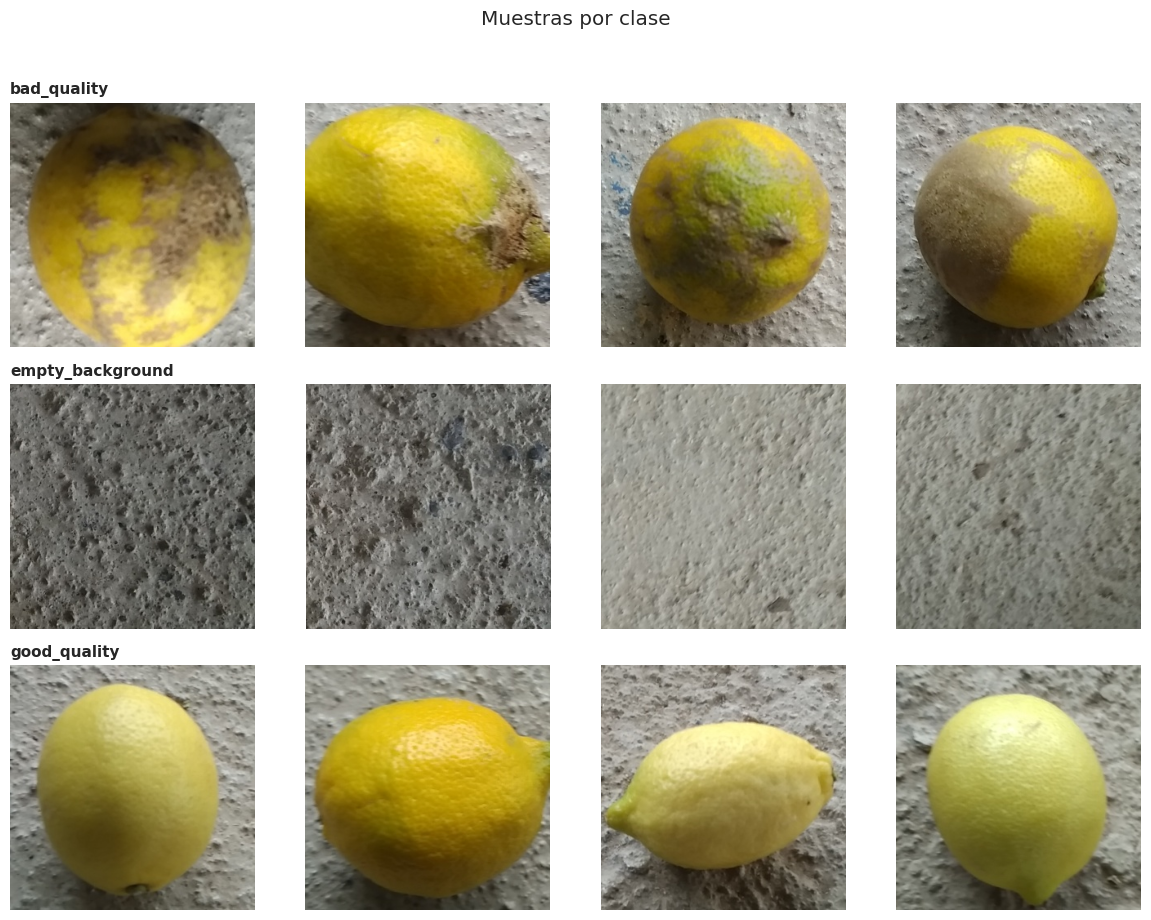

In [7]:
n_samples = 4
classes = sorted(df['clase_origen'].unique())
fig, axes = plt.subplots(len(classes), n_samples, figsize=(12, 9))

for i, cls in enumerate(classes):
    sample = df[df['clase_origen']==cls].sample(n_samples, random_state=42)
    for j, path in enumerate(sample['path'].values):
        img = Image.open(path)
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(cls, loc='left', fontsize=11, fontweight='bold')

plt.suptitle('Muestras por clase', y=1.02)
plt.tight_layout()
plt.show()

## Dimensiones de imágenes

Verificar si todas las imágenes son del mismo tamaño. Si lo son, no necesitamos resize agresivo en `transforms.py`.

In [8]:
dims = []
for path in df['path'].values:
    img = Image.open(path)
    dims.append(img.size)

df['width'] = [d[0] for d in dims]
df['height'] = [d[1] for d in dims]
df['aspect'] = df['width'] / df['height']

print(df[['width', 'height', 'aspect']].describe())
print('\nDimensiones unicas (width x height):')
print(df.groupby(['width','height']).size().reset_index(name='count'))

             width       height       aspect
count  2528.000000  2528.000000  2528.000000
mean    299.998418   299.996835     1.000006
std       0.079556     0.159111     0.000606
min     296.000000   292.000000     0.986667
25%     300.000000   300.000000     1.000000
50%     300.000000   300.000000     1.000000
75%     300.000000   300.000000     1.000000
max     300.000000   300.000000     1.027397

Dimensiones unicas (width x height):
   width  height  count
0    296     300      1
1    300     292      1
2    300     300   2526


## Color promedio por clase

Si Sano y Defectuoso tienen perfiles RGB muy distintos, el clasificador convergerá rápido. Si son similares, hace falta más augmentation o features más finos.

                           R           G           B
clase_origen                                        
bad_quality       144.422378  129.082095   75.081027
empty_background  127.674570  126.536925  120.491942
good_quality      144.944491  138.025191   91.999770


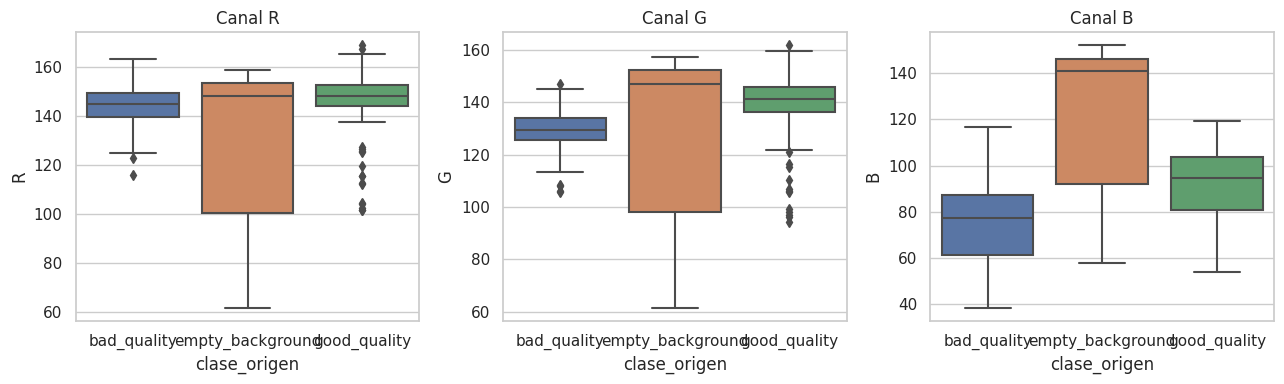

In [10]:
# Submuestra para velocidad: 100 por clase
sample = df.groupby('clase_origen', group_keys=False).apply(lambda x: x.sample(min(100, len(x)), random_state=42))

rgb_rows = []
for _, row in sample.iterrows():
    arr = np.array(Image.open(row['path']).convert('RGB'))
    rgb_rows.append({
        'clase_origen': row['clase_origen'],
        'R': arr[:,:,0].mean(),
        'G': arr[:,:,1].mean(),
        'B': arr[:,:,2].mean(),
    })

rgb_df = pd.DataFrame(rgb_rows)
print(rgb_df.groupby('clase_origen').mean())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for i, ch in enumerate(['R','G','B']):
    sns.boxplot(x='clase_origen', y=ch, data=rgb_df, ax=axes[i])
    axes[i].set_title(f'Canal {ch}')
plt.tight_layout()
plt.show()

## Train / val / test split estratificado

70 / 15 / 15 con stratify por `y`. random_state=42.

In [11]:
X = df_mod_a['path'].values
y = df_mod_a['y'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f'train: {len(X_train)} (sano={int((y_train==0).sum())}, defectuoso={int((y_train==1).sum())})')
print(f'val:   {len(X_val)} (sano={int((y_val==0).sum())}, defectuoso={int((y_val==1).sum())})')
print(f'test:  {len(X_test)} (sano={int((y_test==0).sum())}, defectuoso={int((y_test==1).sum())})')

train: 1453 (sano=787, defectuoso=666)
val:   311 (sano=169, defectuoso=142)
test:  312 (sano=169, defectuoso=143)


## Conclusiones

- **Dataset Modelo A**: 2076 imágenes (1125 Sano + 951 Defectuoso). Ratio 1.18:1, balanceado.
- **Splits estratificados**: train 1453 / val 311 / test 312, `random_state=42`.
- **Dimensiones**: 99.92% son 300×300. `Resize((224,224))` directo, sin crop.
- **RGB**: canal B es el más discriminante (Sano=92, Defectuoso=75). R y G casi iguales.
- **Empty background** (452 imgs): se reserva para validar Modelo B.
- **Arquitectura**: MobileNetV2 con transfer learning, última capa `Linear(1280, 2)`.
- **Augmentation**: `HorizontalFlip`, `Rotation(15)`, `ColorJitter(0.2)`. Sin crops aleatorios.
- **Métrica objetivo**: Accuracy ≥ 90%.